# 01 · Exploratory analysis of paid-media performance

**Question:** where did 20B VND of 2025 media spend go, and which channels earned it back?

**Data:** `data/raw/campaign_daily.csv` — one row per channel per day (spend, impressions,
clicks, conversions, last-click revenue, new customers). Synthetic, seeded.

**Approach:** sanity-check the data, compute the standard funnel metrics (CTR, CVR, CPA, ROAS),
then look at how efficiency moves with spend and over the year. The goal of EDA is to leave
with sharp hypotheses for the regression notebook (`04`), not with conclusions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
PALETTE = {"Facebook Ads": "#2a78d6", "Google Ads": "#eb6834", "TikTok Ads": "#1baf7a",
           "Zalo OA": "#eda100", "Email": "#e87ba4", "Affiliate": "#008300"}

df = pd.read_csv("data/raw/campaign_daily.csv", parse_dates=["date"])
df.head()

,date,channel,spend,impressions,clicks,conversions,revenue,new_customers
0,2025-01-01,Facebook Ads,13404000,168528,3232,76,75889554,38
1,2025-01-02,Facebook Ads,26143000,523202,9116,163,151412329,94
2,2025-01-03,Facebook Ads,27171000,592959,10355,198,184489785,125
3,2025-01-04,Facebook Ads,28434000,702204,12739,227,222390811,140
4,2025-01-05,Facebook Ads,27862000,751567,13333,206,189835353,122


## 1. Data checks before any metric
Missing values, impossible values (clicks > impressions, conversions > clicks), and coverage.

In [4]:
checks = pd.Series({
    "rows": len(df),
    "days": df["date"].nunique(),
    "channels": df["channel"].nunique(),
    "missing_values": int(df.isna().sum().sum()),
    "clicks_gt_impressions": int((df["clicks"] > df["impressions"]).sum()),
    "conversions_gt_clicks": int((df["conversions"] > df["clicks"]).sum()),
    "negative_spend": int((df["spend"] < 0).sum()),
    "zero_spend_days": int((df["spend"] == 0).sum()),
})
checks

rows                     2190
days                      365
channels                    6
missing_values              0
clicks_gt_impressions       0
conversions_gt_clicks       0
negative_spend              0
zero_spend_days             0
dtype: int64

Clean: full year × six channels, no impossible funnel values. Zero-spend days are expected
(email only sends twice a week).

## 2. Channel scorecard

In [7]:
def funnel_metrics(g: pd.DataFrame) -> pd.Series:
    spend, imp, clk, conv, rev = g["spend"].sum(), g["impressions"].sum(), g["clicks"].sum(), g["conversions"].sum(), g["revenue"].sum()
    return pd.Series({
        "spend_M": spend / 1e6, "revenue_M": rev / 1e6, "conversions": conv,
        "CTR_%": 100 * clk / imp, "CVR_%": 100 * conv / clk, "CPC": spend / clk,
        "CPA": spend / conv, "ROAS": rev / spend, "new_customer_%": 100 * g["new_customers"].sum() / conv,
    })

scorecard = df.groupby("channel").apply(funnel_metrics, include_groups=False).sort_values("spend_M", ascending=False)
scorecard["spend_share_%"] = 100 * scorecard["spend_M"] / scorecard["spend_M"].sum()
scorecard["revenue_share_%"] = 100 * scorecard["revenue_M"] / scorecard["revenue_M"].sum()
scorecard.round(2)

,spend_M,revenue_M,conversions,CTR_%,CVR_%,CPC,CPA,ROAS,new_customer_%,spend_share_%,revenue_share_%
channel,,,,,,,,,,,
Facebook Ads,"7,462.72","53,638.56","57,117.00",1.79,1.69,"2,210.21","130,656.63",7.19,62.35,36.08,41.24
Google Ads,"5,762.41","31,044.30","26,867.00",4.49,3.14,"6,742.31","214,478.99",5.39,57.02,27.86,23.87
TikTok Ads,"3,732.13","15,664.36","22,823.00",1.20,0.83,"1,357.22","163,524.91",4.20,73.98,18.04,12.04
Affiliate,"2,077.29","13,547.05","17,479.00",2.49,3.55,"4,219.41","118,845.07",6.52,49.08,10.04,10.41
Zalo OA,"1,402.76","12,466.01","14,404.00",2.99,2.34,"2,279.37","97,386.70",8.89,32.03,6.78,9.58
Email,246.25,"3,718.15","3,622.00",6.00,4.73,"3,214.40","67,987.02",15.10,6.27,1.19,2.86


Two things jump out before any statistics:

* **Google (28% of spend → 24% of revenue) and TikTok (18% → 12%) earn less than their share of
  budget; Zalo OA (7% → 10%) earns more.** Facebook, the biggest line, sits slightly above its
  weight. A budget where two large channels under-deliver and a small one over-delivers is the
  classic shape of allocation by reach rather than by marginal return.
* **Email's ROAS is not comparable** to paid channels — the "spend" is tooling cost, and the
  audience is already acquired. Treat it as a retention channel, not an acquisition one.

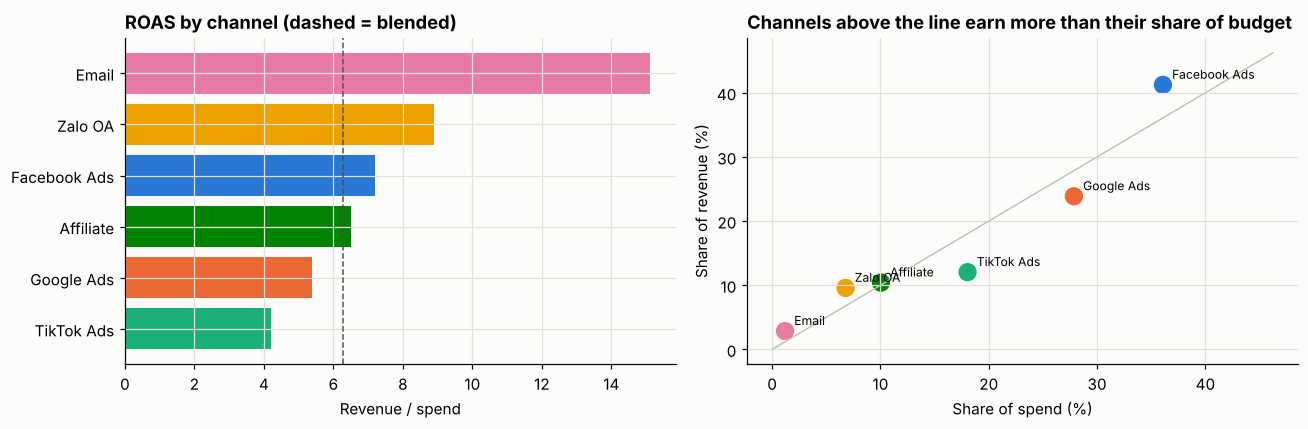

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = scorecard.sort_values("ROAS", ascending=True)
axes[0].barh(order.index, order["ROAS"], color=[PALETTE[c] for c in order.index])
axes[0].axvline(scorecard["revenue_M"].sum() / scorecard["spend_M"].sum(), color="#52514e", ls="--", lw=1)
axes[0].set_title("ROAS by channel (dashed = blended)")
axes[0].set_xlabel("Revenue / spend")
axes[1].scatter(scorecard["spend_share_%"], scorecard["revenue_share_%"], s=120, c=[PALETTE[c] for c in scorecard.index])
lim = max(scorecard["spend_share_%"].max(), scorecard["revenue_share_%"].max()) + 5
axes[1].plot([0, lim], [0, lim], color="#c3c2b7", lw=1)
for ch, r in scorecard.iterrows():
    axes[1].annotate(ch, (r["spend_share_%"], r["revenue_share_%"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[1].set_xlabel("Share of spend (%)"); axes[1].set_ylabel("Share of revenue (%)")
axes[1].set_title("Channels above the line earn more than their share of budget")
plt.tight_layout()

## 3. Does efficiency fall as spend rises? (diminishing returns)
If CVR drops on high-spend days, the marginal VND is worth less than the average VND — which
changes the budget conversation entirely. Bucket each channel's days into spend quintiles.

In [11]:
df["spend_quintile"] = df.groupby("channel")["spend"].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"]))
by_q = (df[df["spend"] > 0].groupby(["channel", "spend_quintile"], observed=True)
          .apply(lambda g: pd.Series({"CVR_%": 100 * g["conversions"].sum() / g["clicks"].sum(),
                                      "CPA_K": g["spend"].sum() / g["conversions"].sum() / 1e3}), include_groups=False)
          .unstack("spend_quintile"))
by_q["CVR_%"].round(2)

spend_quintile,Q1 low,Q2,Q3,Q4,Q5 high
channel,,,,,
Affiliate,3.83,3.80,3.53,3.52,3.32
Email,6.74,5.95,5.44,4.89,3.42
Facebook Ads,1.86,1.72,1.70,1.67,1.59
Google Ads,3.31,3.30,3.14,3.16,2.96
TikTok Ads,0.93,0.85,0.83,0.82,0.77
Zalo OA,2.57,2.45,2.33,2.34,2.17


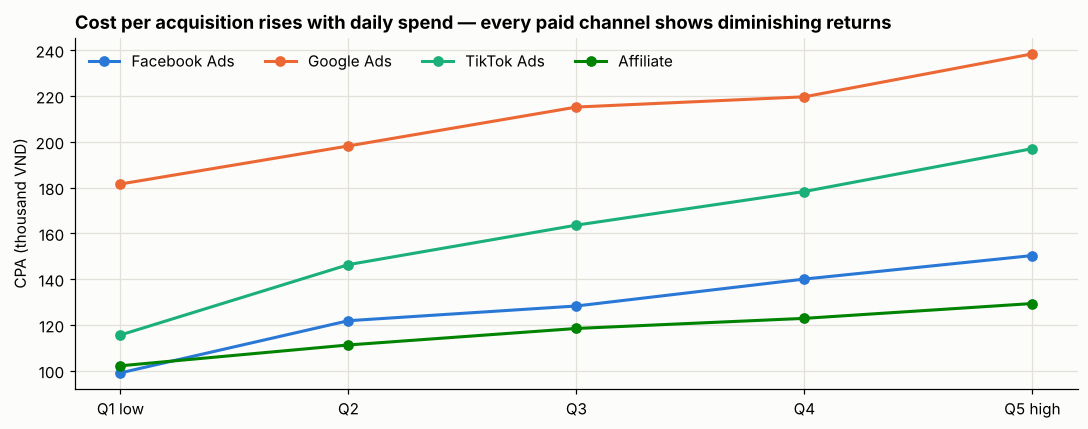

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for ch in ["Facebook Ads", "Google Ads", "TikTok Ads", "Affiliate"]:
    s = by_q.loc[ch, "CPA_K"]
    ax.plot(s.index.astype(str), s.values, marker="o", color=PALETTE[ch], label=ch, lw=2)
ax.set_title("Cost per acquisition rises with daily spend — every paid channel shows diminishing returns")
ax.set_ylabel("CPA (thousand VND)"); ax.legend(frameon=False, ncol=4)
plt.tight_layout()

CPA in the top spend quintile is **1.3–1.7× the bottom quintile** on every paid channel
(TikTok 1.7×, Facebook 1.5×, Zalo 1.5×, Google 1.3×, Affiliate 1.3×). The average ROAS in the
scorecard therefore overstates what the *next* VND would return — this is the central hypothesis
the marketing-mix regression (`04`) will test with elasticities.

## 4. Seasonality and the sale-day spikes

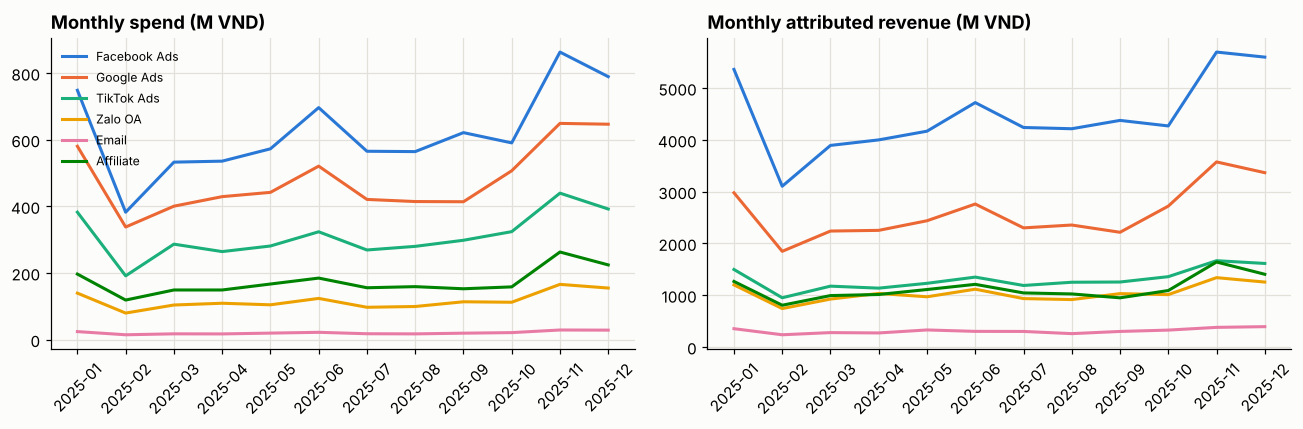

In [15]:
monthly = df.groupby([df["date"].dt.to_period("M"), "channel"])[["spend", "revenue"]].sum().unstack("channel") / 1e6
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ch in PALETTE:
    axes[0].plot(monthly.index.astype(str), monthly[("spend", ch)], color=PALETTE[ch], lw=2, label=ch)
    axes[1].plot(monthly.index.astype(str), monthly[("revenue", ch)], color=PALETTE[ch], lw=2)
axes[0].set_title("Monthly spend (M VND)"); axes[1].set_title("Monthly attributed revenue (M VND)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

In [16]:
daily = df.groupby("date")[["spend", "revenue", "conversions"]].sum()
top_days = daily.sort_values("conversions", ascending=False).head(5)
top_days.assign(ROAS=lambda d: d["revenue"] / d["spend"]).round(2)

,spend,revenue,conversions,ROAS
date,,,,
2025-11-11,190491000,801246368,906,4.21
2025-12-12,162324000,640362162,709,3.94
2025-12-13,81082000,620724620,649,7.66
2025-06-06,136450000,541824146,603,3.97
2025-11-14,79503000,536060492,586,6.74


The sale days (11.11, 12.12, 6.6) deliver the most conversions **and** a ROAS of ~4 against a
yearly blended ~6 — spend was 2.5× normal, conversions did not scale 2.5×. Note the *day after*
each sale also ranks in the top five at a much better ROAS: that is the ad-stock carry-over the
regression notebook models explicitly.

## 5. New-customer mix — acquisition vs. harvesting
ROAS alone rewards channels that re-sell to existing customers. Who actually brings new ones?

In [19]:
newmix = (df.groupby("channel")[["new_customers", "conversions"]].sum()
            .assign(new_share_pct=lambda d: 100 * d["new_customers"] / d["conversions"]).sort_values("new_share_pct"))
newmix.round(1)

,new_customers,conversions,new_share_pct
channel,,,
Email,227,3622,6.30
Zalo OA,4613,14404,32.00
Affiliate,8578,17479,49.10
Google Ads,15320,26867,57.00
Facebook Ads,35611,57117,62.30
TikTok Ads,16884,22823,74.00


**TikTok's 74% new-customer share reframes its weak ROAS**: it is the prospecting channel, and
its conversions should be valued at customer lifetime value, not first-order revenue. Zalo OA
(32%) and Email (6%) are the opposite — high ROAS because they harvest an audience other
channels paid to acquire. Any budget decision that looks at ROAS without this column will
starve prospecting.

## What to take into the next notebooks

| Hypothesis from EDA | Where it gets tested |
|---|---|
| Marginal returns diminish; Facebook is probably past its efficient spend level | `04_regression_marketing_mix` — log-log elasticities with ad-stock |
| Zalo OA is under-funded relative to return; TikTok under-valued by ROAS | `04` — compare elasticities; weight TikTok by new-customer share |
| Sale-day spend is bought at a premium, with carry-over the next day | `04` — ad-stock transform + sale-day dummies |
| Email behaves as retention, not acquisition | treat separately; not in the paid-media model |

EDA stops here. The numbers above are descriptive; none of them is yet a causal claim.